# Seven-cell nested evaluation · GWO-tuned physics-guided SOH forecasting

**Question:** Does soft physics regularization improve next-cycle / 3-cycle / 5-cycle battery SOH prediction **consistently across unseen CALCE CX2 cells**?

**Six matched variants:** Direct Transformer; Direct Transformer + GWO physics; Time-aware Transformer; Time-aware Transformer + GWO physics; CC/CV OLS; CC/CV OLS + GWO physics. OLS physics is constrained regression, **not a PINN**. This is a baseline evaluation of existing methods, not a novel architecture.

**Validation discipline:** Seven outer held-out cells. Inside each outer fold, an *entire different battery* acts as validation; the other five are training batteries. GWO, early stopping and seed selection use the inner validation cell only. The outer battery is used once to report final metrics. Each fold builds its own feature scaler and time scaling; the 3-percentage-point experimental quality filter is applied **only within training cells**. The original validation and outer-test cells are never filtered.

**Prediction task:** Given 12 previous observed charging-feature vectors, predict SOH at 1, 3 and 5 future cycles. No future features or target SOH are inputs. All models use exactly the same eligible windows. **Do not compare these results against current-cycle SOH estimation.**

**Physics caveat:** Soft monotonicity across the three future SOH predictions is a modeling prior, *not* a verified electrochemical governing equation. Measured accessible capacity may recover or fluctuate. `[0, 1.10]` is a pragmatic output bound, not a universal physical range.

**Modes:** `smoke` (1 fold, small window subset, 1 seed), `quick` (3 folds), `full` (7 folds, 3 seeds). Use `smoke` first and `full` for research reporting. **No cross-fold model selection based on outer test errors.**

In [1]:
# Optional, if necessary: %pip install torch numpy pandas scipy scikit-learn matplotlib joblib nbformat
import os, sys, json, hashlib, copy, random, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from scipy.optimize import minimize
import joblib
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cpu':
    torch.set_num_threads(min(4, os.cpu_count() or 1))
print('Device:', DEVICE, 'torch', torch.__version__)

Device: cuda torch 2.11.0+cu128


## 1. Research configuration

Keep the model architectures fixed at the original benchmark settings for the primary comparison. **Only physics-loss weights** are searched by GWO within each inner fold. Increasing search budgets or changing architectural settings after examining outer-fold results would invalidate their status as untouched evaluation folds.

In [2]:
DATA_DIR = Path(os.environ.get('SOH_DATA_DIR', r'C:\Projects\Battery_Soh\pre processed ready to use data'))
RUN_MODE = os.environ.get('SOH_RUN_MODE','full').lower()  # smoke, quick, full
OUTPUT_DIR = DATA_DIR / 'seven_cell_gwo_physics_study' / RUN_MODE
FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
HORIZONS = (1,3,5)
LOOKBACK = 12
MAX_OBSERVED_GAP_H = 24.0
FILTER_JUMP_SOHP = 0.03  # train-only; flags both endpoints for consecutive-cycle jumps
SOH_LOWER, SOH_UPPER = 0.0, 1.10
BATCH_SIZE = 128
SEEDS = [42,123,2026]
MODEL_CONFIG = dict(hidden=48,layers=2,heads=4,ff_mult=2,dropout=0.10,
                    lr=0.001,weight_decay=0.0001)
GWO_LOWER = np.array([0.,0.],dtype=float)
GWO_UPPER = np.array([2.,1.],dtype=float)
# WARNING: smoke and quick output are not publishable model results.
if RUN_MODE=='smoke':
    MAX_FOLDS=1; ACTIVE_SEEDS=[42]; MAX_WINDOWS=100; EPOCHS=2; PATIENCE=2
    GWO_POP=3; GWO_ITERS=1; GWO_EPOCHS=1
elif RUN_MODE=='quick':
    MAX_FOLDS=3; ACTIVE_SEEDS=[42]; MAX_WINDOWS=None; EPOCHS=20; PATIENCE=6
    GWO_POP=4; GWO_ITERS=2; GWO_EPOCHS=5
elif RUN_MODE=='full':
    MAX_FOLDS=None; ACTIVE_SEEDS=SEEDS; MAX_WINDOWS=None; EPOCHS=70; PATIENCE=12
    GWO_POP=6; GWO_ITERS=4; GWO_EPOCHS=10
else: raise ValueError('RUN_MODE must be smoke, quick or full')
RESUME=True
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
assert len(HORIZONS)==3 and tuple(sorted(HORIZONS))==HORIZONS
print('Data:',DATA_DIR,'\nOutput:',OUTPUT_DIR,'\nMode:',RUN_MODE)

Data: C:\Projects\Battery_Soh\pre processed ready to use data 
Output: C:\Projects\Battery_Soh\pre processed ready to use data\seven_cell_gwo_physics_study\full 
Mode: full


## 2. Load all seven cells from the original partition files

The original `train.csv`, `validation.csv` and `test.csv` are reunited **only to define new, independent outer battery folds**. The prior `train_final_filtered.csv` is intentionally *not* used, because its exclusion decisions were derived under an older split. New exclusions are learned inside each fold's training cells.

In [3]:
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for part in iter(lambda:f.read(2**20),b''): h.update(part)
    return h.hexdigest()

def read_and_check(path):
    if not path.exists(): raise FileNotFoundError(f'Missing file: {path}')
    df=pd.read_csv(path)
    required=['battery','cycle_ordinal','cycle_start','soh']+FEATURES
    missing=set(required)-set(df.columns)
    if missing: raise ValueError(f'{path.name}: missing {missing}')
    df['cycle_start']=pd.to_datetime(df['cycle_start'],errors='raise')
    if df[required].isna().any().any():raise ValueError('Missing required values: '+path.name)
    if not np.isfinite(df[FEATURES+['soh']].to_numpy(dtype=float)).all():
        raise ValueError('Non-finite values: '+path.name)
    return df

source_files=[DATA_DIR/f for f in ('train.csv','validation.csv','test.csv')]
original_parts=[read_and_check(f) for f in source_files]
all_df=pd.concat(original_parts,ignore_index=True)
all_df=all_df.sort_values(['battery','cycle_ordinal']).reset_index(drop=True)
assert not all_df.duplicated(['battery','cycle_ordinal']).any(),'Duplicated battery/cycle'
CELLS=sorted(all_df['battery'].astype(str).unique().tolist())
assert len(CELLS)==7, f'Expected 7 cells, found {CELLS}'
input_hashes={f.name:sha256(f) for f in source_files}
print('Battery counts:')
display(all_df.groupby('battery').agg(rows=('soh','size'),min_soh=('soh','min'),max_soh=('soh','max')))
print('SHA256 inputs:',input_hashes)

Battery counts:


,rows,min_soh,max_soh
battery,,,
CX2_16,1899,0.593240,0.943429
CX2_33,1488,0.473168,0.959999
CX2_34,1554,0.480762,1.003656
CX2_35,1630,0.442747,1.011827
CX2_36,1743,0.469368,1.007746
CX2_37,1219,0.607048,1.012100
CX2_38,1477,0.472186,1.009452


SHA256 inputs: {'train.csv': 'fd5dc165182f1e19445e2b59eb8f63ddf092ebd59c38bc5c98de6478aa89a415', 'validation.csv': 'd7660fb27575f8939e8d55b1771892bd611f8c042dada331edee05bb406cd659', 'test.csv': 'ad7c1f39bee4b7d076af3c9f019c86c5ea2498190d7709db29420c218aba9b34'}


## 3. Outer cell and inner validation design

For each held-out cell, choose the **next cell in sorted order** as inner validation. The remaining five cells are training cells. This is a fixed, transparent design rather than a random cycle-level split. Full nested cell-level validation with several inner folds would be stronger but more expensive; this notebook uses one predeclared inner validation cell per outer fold.

In [4]:
def make_folds(cells):
    return [dict(heldout=c,inner_val=cells[(i+1)%len(cells)],
                 train_cells=[v for v in cells if v not in (c,cells[(i+1)%len(cells)])])
            for i,c in enumerate(cells)]
FOLDS=make_folds(CELLS)
if MAX_FOLDS is not None:FOLDS=FOLDS[:MAX_FOLDS]
display(pd.DataFrame(FOLDS))
assert all(len(f['train_cells'])==5 for f in FOLDS)

# Drop only experimental training outlier endpoints; do not re-number cycles.
def filter_training(frame, threshold=FILTER_JUMP_SOHP):
    df=frame.sort_values(['battery','cycle_ordinal']).copy()
    g=df.groupby('battery',sort=False)
    jump=(g['cycle_ordinal'].diff().eq(1) & g['soh'].diff().abs().gt(threshold))
    prev=jump.groupby(df['battery']).shift(-1,fill_value=False)
    remove=(jump | prev)
    audit=df.loc[remove,['battery','cycle_ordinal','soh']].copy()
    audit['reason']='adjacent_endpoint_of_SOHP_jump_gt_'+str(threshold)
    return df.loc[~remove].copy(),audit

filtered_example,audit_example=filter_training(all_df[all_df.battery.isin(FOLDS[0]['train_cells'])])
print('Train-only filter demo (fold 1):',len(filtered_example),'retained,',len(audit_example),'flagged')

,heldout,inner_val,train_cells
0,CX2_16,CX2_33,"[CX2_34, CX2_35, CX2_36, CX2_37, CX2_38]"
1,CX2_33,CX2_34,"[CX2_16, CX2_35, CX2_36, CX2_37, CX2_38]"
2,CX2_34,CX2_35,"[CX2_16, CX2_33, CX2_36, CX2_37, CX2_38]"
3,CX2_35,CX2_36,"[CX2_16, CX2_33, CX2_34, CX2_37, CX2_38]"
4,CX2_36,CX2_37,"[CX2_16, CX2_33, CX2_34, CX2_35, CX2_38]"
5,CX2_37,CX2_38,"[CX2_16, CX2_33, CX2_34, CX2_35, CX2_36]"
6,CX2_38,CX2_16,"[CX2_33, CX2_34, CX2_35, CX2_36, CX2_37]"


Train-only filter demo (fold 1): 7615 retained, 8 flagged


## 4. Create identical, leakage-safe forecasting windows

Windows are drawn from physically ordered contiguous records inside one cell. A window is broken when the cycle ordinal skips, timestamps go backward, or the start-to-start interval exceeds 24 h. Such intervals are **unknown history**, not proven rest. The elapsed-time channel is normalized using only the fold's training segments. This conservative gap rule can exclude valuable data; report eligibility counts and study sensitivity in a later analysis.

In [5]:
def contiguous_segments(frame, min_len=1, max_gap=MAX_OBSERVED_GAP_H):
    for battery,g in frame.groupby('battery',sort=True):
        g=g.sort_values('cycle_ordinal').reset_index(drop=True)
        dc=g.cycle_ordinal.diff()
        dt=g.cycle_start.diff().dt.total_seconds()/3600
        new=(dc.ne(1)|dt.le(0)|dt.gt(max_gap)).fillna(True)
        for _,seg in g.groupby(new.cumsum()):
            if len(seg)>=min_len:yield str(battery),seg.reset_index(drop=True)

def fold_dt_scale(frame):
    pieces=[]
    for _,seg in contiguous_segments(frame,min_len=2):
        pieces.extend((seg.cycle_start.diff().dt.total_seconds().iloc[1:]/3600).tolist())
    if not pieces: raise ValueError('No eligible training intervals')
    ans=float(np.median(pieces))
    assert np.isfinite(ans) and ans>0
    return ans

class ForecastWindows(Dataset):
    def __init__(self,frame,scaler,dt_scale,max_windows=None):
        rows=[]
        for battery,seg in contiguous_segments(frame,min_len=LOOKBACK+max(HORIZONS)):
            features=scaler.transform(seg[FEATURES]).astype(np.float32)
            target=seg['soh'].to_numpy(dtype=np.float32)
            cy=seg['cycle_ordinal'].to_numpy(dtype=np.int64)
            delta=seg.cycle_start.diff().dt.total_seconds().to_numpy()/3600
            dt=np.ones(len(seg),dtype=np.float32)
            dt[1:]=(delta[1:]/dt_scale).astype(np.float32)
            for last in range(LOOKBACK-1,len(seg)-max(HORIZONS)):
                begin=last-LOOKBACK+1
                xs=features[begin:last+1].copy()
                ts=dt[begin:last+1].copy();ts[0]=1.0  # no prior interval within window
                ys=np.asarray([target[last+h] for h in HORIZONS],dtype=np.float32)
                tc=np.asarray([cy[last+h] for h in HORIZONS],dtype=np.int64)
                assert np.array_equal(tc-cy[last],np.array(HORIZONS))
                rows.append((xs,ts,ys,battery,int(cy[last]),tc))
        if max_windows is not None and len(rows)>max_windows:
            rng=np.random.default_rng(1001)
            ids=np.sort(rng.choice(len(rows),max_windows,replace=False))
            rows=[rows[j] for j in ids]
        self.rows=rows
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):return self.rows[i]

def build_fold(fold):
    raw_train=all_df[all_df.battery.isin(fold['train_cells'])].copy()
    fit_train,audit=filter_training(raw_train)
    inner_val=all_df[all_df.battery.eq(fold['inner_val'])].copy()
    heldout=all_df[all_df.battery.eq(fold['heldout'])].copy()
    assert not (set(fit_train.battery)&set(inner_val.battery) or set(fit_train.battery)&set(heldout.battery))
    scaler=StandardScaler().fit(fit_train[FEATURES])
    dt_scale=fold_dt_scale(fit_train)
    tr=ForecastWindows(fit_train,scaler,dt_scale,MAX_WINDOWS)
    va=ForecastWindows(inner_val,scaler,dt_scale,MAX_WINDOWS)
    te=ForecastWindows(heldout,scaler,dt_scale,MAX_WINDOWS)
    if not min(map(len,(tr,va,te)))>0:
        raise ValueError(f'Not enough contiguous windows in {fold}: {[len(z) for z in (tr,va,te)]}')
    return dict(train=tr,val=va,test=te,scaler=scaler,dt_scale=dt_scale,
                train_raw=raw_train,train_filtered=fit_train,filter_audit=audit)

fold_example=build_fold(FOLDS[0])
print('First fold eligible windows:',{s:len(fold_example[s]) for s in ('train','val','test')})

First fold eligible windows: {'train': 2635, 'val': 476, 'test': 833}


## 5. Fixed models and explicit, limited physics priors

**Monotonicity penalty:** penalizes positive changes among predictions for the same forecasting origin at horizons 1→3→5, not between arbitrary consecutive data rows. **Bounds penalty:** penalizes predictions outside `[0, 1.10]`. Both are *soft phenomenological priors*; this is not an electrochemical PDE PINN. Importantly, target measured SOH may itself increase.

Training uses the same architecture and MSE baseline for all physics variants. The physical-loss terms affect only the penalized versions.

In [6]:
class HorizonHead(nn.Module):
    def __init__(self,width):
        super().__init__()
        self.layers=nn.Sequential(nn.Linear(width+1,width),nn.GELU(),nn.Linear(width,1))
    def forward(self,z,h):
        return self.layers(torch.cat((z,h.reshape(-1,1)/max(HORIZONS)),axis=-1)).squeeze(-1)

class SOHTransformer(nn.Module):
    def __init__(self,time_aware=False,**cfg):
        super().__init__()
        hidden=cfg['hidden'];heads=cfg['heads']
        assert hidden%heads==0
        self.time_aware=time_aware
        self.embedding=nn.Linear(len(FEATURES)+int(time_aware),hidden)
        self.pos=nn.Parameter(torch.zeros(1,LOOKBACK,hidden))
        layer=nn.TransformerEncoderLayer(d_model=hidden,nhead=heads,
            dim_feedforward=hidden*cfg['ff_mult'],dropout=cfg['dropout'],
            batch_first=True,norm_first=True,activation='relu')
        self.encoder=nn.TransformerEncoder(layer,num_layers=cfg['layers'],enable_nested_tensor=False)
        self.head=HorizonHead(hidden)
    def forward_all(self,x,dt):
        if self.time_aware:
            x=torch.cat((x,torch.log1p(dt.clamp_min(0.)).unsqueeze(-1)),axis=-1)
        z=self.encoder(self.embedding(x)+self.pos)[:,-1,:]
        b=len(z)
        horizons=torch.tensor(HORIZONS,dtype=z.dtype,device=z.device).expand(b,-1)
        return self.head(z.unsqueeze(1).expand(-1,len(HORIZONS),-1).reshape(-1,z.shape[-1]),
                         horizons.reshape(-1)).reshape(b,len(HORIZONS))

def physics_loss(pred):
    mono=F.relu(pred[:,1]-pred[:,0]).square().mean()+F.relu(pred[:,2]-pred[:,1]).square().mean()
    bound=(F.relu(SOH_LOWER-pred).square()+F.relu(pred-SOH_UPPER).square()).mean()
    return mono,bound

def total_loss(pred,target,weights):
    mono,bound=physics_loss(pred)
    return F.mse_loss(pred,target)+float(weights[0])*mono+float(weights[1])*bound

def get_model(family):
    return SOHTransformer(time_aware=(family=='time_transformer'),**
                          {k:MODEL_CONFIG[k] for k in ('hidden','layers','heads','ff_mult','dropout')})

def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

def data_loader(ds,shuffle=False):
    return DataLoader(ds,batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0)

# Forward + gradient + no-future-input checks
seed_all(42)
for fam in ('direct_transformer','time_transformer'):
    mod=get_model(fam).to(DEVICE)
    x=torch.randn(4,LOOKBACK,5,device=DEVICE)
    dt=torch.ones(4,LOOKBACK,device=DEVICE)
    pred=mod.forward_all(x,dt)
    total_loss(pred,torch.rand_like(pred),[0.1,0.1]).backward()
    assert pred.shape==(4,3) and torch.isfinite(pred).all()
print('Model shapes and gradient paths verified')

Model shapes and gradient paths verified


## 6. Training, selection and prediction

Validation selection minimizes the **mean of the three horizon-specific RMSE values**, so one horizon cannot dominate simply because of scale. All three targets are reported separately in every outer fold.

In [7]:
def make_prediction_frame(ds,all_preds):
    rows=[]
    for item,p in zip(ds.rows,all_preds):
        _,_,y,battery,last,target_cycles=item
        for j,h in enumerate(HORIZONS):
            rows.append(dict(battery=battery,last_input_cycle=last,
                             target_cycle=int(target_cycles[j]),horizon=h,
                             soh_true=float(y[j]),soh_pred=float(p[j])))
    return pd.DataFrame(rows)

@torch.no_grad()
def neural_predict(model,ds):
    model.eval();chunks=[]
    for xb,dtb,yb,*_ in data_loader(ds):
        chunks.append(model.forward_all(xb.to(DEVICE),dtb.to(DEVICE)).cpu().numpy())
    return make_prediction_frame(ds,np.vstack(chunks))

def score_metrics(p):
    y=p.soh_true.to_numpy(float);pred=p.soh_pred.to_numpy(float)
    return dict(RMSE=float(np.sqrt(np.mean((y-pred)**2))),
                MAE=float(np.mean(np.abs(y-pred))),
                MAPE=float(np.mean(np.abs(y-pred)/np.maximum(np.abs(y),1e-6))*100),
                R2=float(r2_score(y,pred)) if len(y)>1 and np.var(y)>0 else np.nan,
                n=len(y))

def objective_metric(df):
    return float(np.mean([score_metrics(part)['RMSE'] for _,part in df.groupby('horizon')]))

def train_net(family,fold_data,weights,seed,epochs,patience,checkpoint=None):
    seed_all(seed)
    model=get_model(family).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=MODEL_CONFIG['lr'],
                          weight_decay=MODEL_CONFIG['weight_decay'])
    best=np.inf;bad=0;best_epoch=0;best_state=None;history=[]
    start=time.perf_counter()
    for epoch in range(1,epochs+1):
        model.train();s=0.;cnt=0
        for x,dt,y,*_ in data_loader(fold_data['train'],shuffle=True):
            x=x.to(DEVICE);dt=dt.to(DEVICE);y=y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            pred=model.forward_all(x,dt)
            loss=total_loss(pred,y,weights)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.0)
            opt.step()
            s+=loss.item()*len(y);cnt+=len(y)
        vp=neural_predict(model,fold_data['val'])
        val=objective_metric(vp)
        history.append(dict(epoch=epoch,train_loss=s/max(cnt,1),validation_mean_horizon_RMSE=val))
        if val<best-1e-7:
            best=val;best_epoch=epoch;bad=0;best_state=copy.deepcopy(model.state_dict())
        else:
            bad+=1
            if bad>=patience:break
    model.load_state_dict(best_state)
    info=dict(seed=int(seed),family=family,weights=np.asarray(weights).tolist(),
              selected_epoch=int(best_epoch),inner_validation_RMSE=float(best),
              seconds=float(time.perf_counter()-start))
    if checkpoint is not None:
        torch.save(dict(state_dict=model.state_dict(),info=info,config=MODEL_CONFIG,
                        features=FEATURES,horizons=HORIZONS,lookback=LOOKBACK,
                        dt_scale_h=fold_data['dt_scale'],
                        scaler_mean=fold_data['scaler'].mean_.tolist(),
                        scaler_scale=fold_data['scaler'].scale_.tolist()),checkpoint)
    return model,info,pd.DataFrame(history)

## 7. Linear regression with physics penalties and GWO

OLS uses the **last available** standardized CC/CV duration and forecast horizon. When physics weights are zero, it is ordinary unpenalized least squares. Nonzero weights produce **physics-penalized linear regression**, not a physics-informed neural network. The same `MSE + λ_mono L_mono + λ_bound L_bound` objective is optimized with L-BFGS-B on the small coefficient vector.

In [8]:
def ols_design(ds):
    X=[];Y=[]
    for obs,dt,y,battery,last,targets in ds.rows:
        h=np.asarray(HORIZONS,dtype=float)/max(HORIZONS)
        design=np.column_stack((np.ones(3),np.tile(obs[-1,:2],(3,1)),h))
        X.append(design);Y.append(y)
    return np.asarray(X,dtype=float),np.asarray(Y,dtype=float)

class LinearSOH:
    def __init__(self,beta):self.beta=np.asarray(beta,dtype=float)
    def predict_all(self,X):return X@self.beta

def fit_linear(fold_data,weights):
    X,Y=ols_design(fold_data['train'])
    beta0=np.linalg.lstsq(X.reshape(-1,4),Y.reshape(-1),rcond=None)[0]
    if np.allclose(weights,[0,0]):return LinearSOH(beta0)
    xx=torch.tensor(X,dtype=torch.float64);yy=torch.tensor(Y,dtype=torch.float64)
    def opt_fn(vec):
        beta=torch.tensor(vec,dtype=torch.float64,requires_grad=True)
        pred=xx@beta
        loss=total_loss(pred,yy,weights)
        grad=torch.autograd.grad(loss,beta)[0]
        return float(loss.detach()),grad.detach().numpy()
    sol=minimize(opt_fn,beta0,jac=True,method='L-BFGS-B',
                 options=dict(maxiter=250,ftol=1e-12))
    if not sol.success and np.linalg.norm(sol.jac)>1e-4:
        warnings.warn('Penalized OLS optimization did not fully converge: '+str(sol.message))
    return LinearSOH(sol.x)

def linear_predict(model,ds):
    X,_=ols_design(ds)
    return make_prediction_frame(ds,model.predict_all(X))

# No predicted target is an input; fixed-size OLS design proof
X0,y0=ols_design(fold_example['train'])
assert X0.shape[1:]==(3,4) and y0.shape[1:]==(3,)
print('OLS design verified:',X0.shape)

OLS design verified: (2635, 3, 4)


## 8. Grey Wolf Optimization (inner validation only)

GWO optimizes **two loss coefficients**, not the neural network's millions of weights. Each candidate is evaluated with an equal, short training budget on the *current fold's training cells*, and scored on the *current fold's inner validation cell*. The full-budget trained model is subsequently retrained from scratch with the chosen weights.

**Caveat:** Short-budget fitness is only a proxy for final performance. The optimizer can overfit one inner validation cell. A stronger study would nest GWO inside several inner cell folds; this notebook explicitly reports that limitation.

In [9]:
def gwo_search(fitness,lower,upper,nwolves,niter,seed):
    rng=np.random.default_rng(seed)
    positions=rng.uniform(lower,upper,(nwolves,len(lower)))
    positions[0]=lower.copy() # zero-weight control is a candidate
    seen={};records=[]
    def evaluate(p,step,wolf):
        key=tuple(np.round(p,6))
        if key not in seen: seen[key]=float(fitness(p))
        score=seen[key]
        records.append(dict(iteration=int(step),wolf=int(wolf),lambda_mono=float(p[0]),
                            lambda_bound=float(p[1]),validation_score=score))
        return score
    for step in range(niter+1):
        scores=np.asarray([evaluate(p,step,k) for k,p in enumerate(positions)])
        leaders=positions[np.argsort(scores)[:3]].copy()
        if step==niter:break
        a=2*(1-step/max(niter,1))
        new=[]
        for pos in positions:
            estimates=[]
            for leader in leaders:
                A=2*a*rng.random(len(lower))-a
                C=2*rng.random(len(lower))
                estimates.append(leader-A*np.abs(C*leader-pos))
            new.append(np.clip(np.mean(estimates,axis=0),lower,upper))
        positions=np.asarray(new)
        positions[0]=leaders[0] # preserve best agent
    hist=pd.DataFrame(records)
    hist=hist.sort_values(['validation_score','lambda_mono','lambda_bound'])
    best=hist.iloc[0]
    return np.asarray([best.lambda_mono,best.lambda_bound]),pd.DataFrame(records)

# Synthetic sanity check
z,gh=gwo_search(lambda a:(a[0]-0.4)**2+(a[1]-0.2)**2,
                GWO_LOWER,GWO_UPPER,3,1,42)
assert len(z)==2 and np.all(z>=GWO_LOWER) and np.all(z<=GWO_UPPER)

def tune_weights(family,data,fold_id):
    def fitness(weights):
        if family=='ols_last_CC_CV':
            return objective_metric(linear_predict(fit_linear(data,weights),data['val']))
        _,info,_=train_net(family,data,weights,seed=42,
                          epochs=GWO_EPOCHS,patience=GWO_EPOCHS)
        return info['inner_validation_RMSE']
    weights,hist=gwo_search(fitness,GWO_LOWER,GWO_UPPER,GWO_POP,GWO_ITERS,seed=1234+fold_id)
    hist.insert(0,'family',family)
    return weights,hist

## 9. Physical-consistency and observed-label diagnostics

Report **both**: (a) monotonic increases in the model's predicted SOH horizons, and (b) increases in the *measured target SOH* for those horizons. Penalizing the former despite the latter may improve visual smoothness at the cost of real-data accuracy. We also report violation *magnitude* in SOH percentage points rather than counting events alone.

In [10]:
def physics_diagnostics(pred_df):
    p=pred_df.pivot(index=['battery','last_input_cycle'],columns='horizon',values='soh_pred')
    t=pred_df.pivot(index=['battery','last_input_cycle'],columns='horizon',values='soh_true')
    pred=p[list(HORIZONS)].to_numpy(float)
    target=t[list(HORIZONS)].to_numpy(float)
    inc_pred=np.maximum(np.diff(pred,axis=1),0.)
    inc_true=np.maximum(np.diff(target,axis=1),0.)
    return dict(pred_violation_fraction=float((inc_pred>1e-8).any(axis=1).mean()),
                pred_mean_increase_pp=float(100*inc_pred.sum(axis=1).mean()),
                true_increase_fraction=float((inc_true>1e-8).any(axis=1).mean()),
                true_mean_increase_pp=float(100*inc_true.sum(axis=1).mean()),
                out_of_bounds_fraction=float(((pred<SOH_LOWER)|(pred>SOH_UPPER)).any(axis=1).mean()),
                n_origins=int(len(pred)))

# Verify violation detection and positivity, independently of training
r=physics_diagnostics(pd.DataFrame([
    dict(battery='x',last_input_cycle=12,horizon=h,soh_pred=p,soh_true=t)
    for h,p,t in [(1,0.70,0.7),(3,0.71,0.69),(5,0.68,0.72)]]))
assert r['pred_violation_fraction']==1 and r['pred_mean_increase_pp']>0

## 10. Run the cross-cell experiment

Each fold saves its scaler, training-exclusion audit, GWO search, seed-specific training histories, best validation-selected checkpoint, held-out prediction CSVs, and metrics. Runs are resumable through a per-fold completion marker. The `full` mode evaluates seven held-out cells and never changes model configuration in response to those results.

**Fairness:** All six variants use the *same training windows and targets*. The GWO weight search is separate per family and per outer fold. The baseline and physics variants of each Transformer have the same backbone width and seed candidates.

In [11]:
FAMILIES=('direct_transformer','time_transformer','ols_last_CC_CV')
VARIANTS=('baseline','physics_gwo')
run_config=dict(run_mode=RUN_MODE,features=FEATURES,horizons=HORIZONS,
                lookback=LOOKBACK,max_gap_hours=MAX_OBSERVED_GAP_H,
                train_filter_threshold_SOHP=FILTER_JUMP_SOHP,
                bounds=[SOH_LOWER,SOH_UPPER],seeds=ACTIVE_SEEDS,epochs=EPOCHS,
                gwo_population=GWO_POP,gwo_iterations=GWO_ITERS,
                gwo_candidate_epochs=GWO_EPOCHS,model_config=MODEL_CONFIG,
                source_hashes=input_hashes)
run_digest=hashlib.sha256(json.dumps(run_config,sort_keys=True).encode()).hexdigest()
(OUTPUT_DIR/'CONFIG.json').write_text(json.dumps({**run_config,'run_digest':run_digest},indent=2),encoding='utf-8')

def run_fold(fold,fold_i):
    tag=f'{fold_i+1:02d}_{fold["heldout"]}'
    folder=OUTPUT_DIR/tag;folder.mkdir(parents=True,exist_ok=True)
    done=folder/'COMPLETED.json'
    if RESUME and done.exists():
        old=json.loads(done.read_text())
        if old.get('run_digest')==run_digest and (folder/'outer_metrics.csv').exists():
            print('RESUMED',tag)
            return pd.read_csv(folder/'outer_metrics.csv'),pd.read_csv(folder/'inner_selection.csv'),pd.read_csv(folder/'physics_diagnostics.csv')
    data=build_fold(fold)
    data['filter_audit'].to_csv(folder/'training_exclusions.csv',index=False)
    joblib.dump(data['scaler'],folder/'feature_scaler.joblib')
    fold_meta=dict(**fold,train_rows_before=len(data['train_raw']),train_rows_after=len(data['train_filtered']),
                   n_filtered=len(data['filter_audit']),windows={x:len(data[x]) for x in ('train','val','test')},
                   dt_scale_h=data['dt_scale'],run_digest=run_digest)
    (folder/'fold_meta.json').write_text(json.dumps(fold_meta,indent=2),encoding='utf-8')
    print('FOLD',tag,'train/val/test windows:',fold_meta['windows'])
    weights_by_family={};gwo_log=[]
    for family in FAMILIES:
        w,history=tune_weights(family,data,fold_i)
        weights_by_family[family]=w
        history.insert(0,'heldout',fold['heldout'])
        gwo_log.append(history)
        print('GWO',family,'weights',np.round(w,4))
    pd.concat(gwo_log,ignore_index=True).to_csv(folder/'gwo_search.csv',index=False)
    result=[];selection=[];diagnostics=[];training_hist=[]
    for family in FAMILIES:
        for variant in VARIANTS:
            weights=np.array([0.,0.]) if variant=='baseline' else weights_by_family[family]
            candidates=[]
            if family=='ols_last_CC_CV':
                model=fit_linear(data,weights)
                vp=linear_predict(model,data['val'])
                val=objective_metric(vp)
                cp=folder/f'{family}_{variant}.joblib'
                joblib.dump(dict(coefficients=model.beta,weights=weights.tolist(),
                     features=['cc_duration_s','cv_duration_s'],model='ols_last_CC_CV'),cp)
                candidates.append((val,42,model,str(cp)))
            else:
                for seed in ACTIVE_SEEDS:
                    cp=folder/f'{family}_{variant}_seed{seed}.pt'
                    net,info,hist=train_net(family,data,weights,seed,EPOCHS,PATIENCE,checkpoint=cp)
                    hist.insert(0,'seed',seed);hist.insert(0,'variant',variant);hist.insert(0,'model',family)
                    training_hist.append(hist)
                    candidates.append((info['inner_validation_RMSE'],seed,net,str(cp)))
            # Validation-only seed choice. All outer held-out predictions happen after this.
            val,seed,best,cp=min(candidates,key=lambda e:(e[0],e[1]))
            record=dict(heldout=fold['heldout'],inner_val=fold['inner_val'],model=family,
                        variant=variant,seed=seed,validation_score=val,
                        lambda_mono=float(weights[0]),lambda_bound=float(weights[1]),checkpoint=cp)
            selection.append(record)
            get_preds=linear_predict if family=='ols_last_CC_CV' else neural_predict
            vdf=get_preds(best,data['val']);tdf=get_preds(best,data['test'])
            vdf.to_csv(folder/f'{family}_{variant}_inner_validation_predictions.csv',index=False)
            tdf.to_csv(folder/f'{family}_{variant}_outer_predictions.csv',index=False)
            for split,pdf in [('inner_val',vdf),('outer_test',tdf)]:
                diag=physics_diagnostics(pdf)
                diagnostics.append(dict(heldout=fold['heldout'],model=family,variant=variant,split=split,**diag))
                for horizon,piece in pdf.groupby('horizon'):
                    result.append(dict(heldout=fold['heldout'],inner_val=fold['inner_val'],
                                       model=family,variant=variant,seed=seed,split=split,
                                       horizon=int(horizon),**score_metrics(piece)))
            print(f'   {family} / {variant}: inner val {val:.5f} | outer RMSE '+
                  ', '.join(f'{x:.5f}' for x in [score_metrics(p)['RMSE'] for _,p in tdf.groupby('horizon')]))
    pd.DataFrame(result).to_csv(folder/'outer_metrics.csv',index=False)
    pd.DataFrame(selection).to_csv(folder/'inner_selection.csv',index=False)
    pd.DataFrame(diagnostics).to_csv(folder/'physics_diagnostics.csv',index=False)
    if training_hist:pd.concat(training_hist,ignore_index=True).to_csv(folder/'training_histories.csv',index=False)
    done.write_text(json.dumps(dict(run_digest=run_digest,heldout=fold['heldout']),indent=2))
    return pd.DataFrame(result),pd.DataFrame(selection),pd.DataFrame(diagnostics)

metrics_chunks=[];selections_chunks=[];diagnostic_chunks=[]
for i,fold in enumerate(FOLDS):
    mets,sels,diags=run_fold(fold,i)
    metrics_chunks.append(mets);selections_chunks.append(sels);diagnostic_chunks.append(diags)
metrics_all=pd.concat(metrics_chunks,ignore_index=True)
selection_all=pd.concat(selections_chunks,ignore_index=True)
physics_all=pd.concat(diagnostic_chunks,ignore_index=True)
metrics_all.to_csv(OUTPUT_DIR/'all_fold_metrics.csv',index=False)
selection_all.to_csv(OUTPUT_DIR/'all_fold_validation_selections.csv',index=False)
physics_all.to_csv(OUTPUT_DIR/'all_fold_physics_diagnostics.csv',index=False)
print('Finished outer folds:',len(FOLDS))

FOLD 01_CX2_16 train/val/test windows: {'train': 2635, 'val': 476, 'test': 833}
GWO direct_transformer weights [2.     0.6768]
GWO time_transformer weights [1.9169 0.5506]
GWO ols_last_CC_CV weights [0. 0.]
   direct_transformer / baseline: inner val 0.01158 | outer RMSE 0.01852, 0.02010, 0.02052
   direct_transformer / physics_gwo: inner val 0.01163 | outer RMSE 0.01816, 0.01996, 0.02064
   time_transformer / baseline: inner val 0.01202 | outer RMSE 0.02323, 0.02279, 0.02174
   time_transformer / physics_gwo: inner val 0.01174 | outer RMSE 0.02256, 0.02247, 0.02169
   ols_last_CC_CV / baseline: inner val 0.01158 | outer RMSE 0.01520, 0.01947, 0.01907
   ols_last_CC_CV / physics_gwo: inner val 0.01158 | outer RMSE 0.01520, 0.01947, 0.01907
FOLD 02_CX2_33 train/val/test windows: {'train': 2930, 'val': 435, 'test': 476}
GWO direct_transformer weights [1.3718 0.4757]
GWO time_transformer weights [1.4288 1.    ]
GWO ols_last_CC_CV weights [0. 0.]
   direct_transformer / baseline: inner val

## 11. Fold-level comparison and reliability diagnostics

**Primary endpoint:** mean outer-fold RMSE per horizon, counting each cell equally. Fold variability (SD) is not a significance test. Also report *paired* per-cell RMSE changes (physics minus baseline): negative means physics helped. The scatter of cells is more informative than a pooled cycle-weighted average.

Do not change the model based on this table and then call it a fresh held-out test; a new evaluation protocol would be needed for a newly proposed method.

In [12]:
outer=metrics_all.query('split=="outer_test"').copy()
summary=(outer.groupby(['model','variant','horizon'],as_index=False)
         .agg(mean_fold_RMSE=('RMSE','mean'),std_fold_RMSE=('RMSE','std'),
              mean_fold_MAE=('MAE','mean'),mean_fold_R2=('R2','mean'),n_cells=('heldout','nunique')))
summary.to_csv(OUTPUT_DIR/'cross_cell_summary.csv',index=False)
base=outer.query('variant=="baseline"')[["heldout","model","horizon","RMSE"]].rename(columns={'RMSE':'baseline_RMSE'})
phys=outer.query('variant=="physics_gwo"')[["heldout","model","horizon","RMSE"]].rename(columns={'RMSE':'physics_RMSE'})
paired=base.merge(phys,on=['heldout','model','horizon'],validate='one_to_one')
paired['delta_RMSE']=paired['physics_RMSE']-paired['baseline_RMSE']
paired['improvement_pct']=100*(paired['baseline_RMSE']-paired['physics_RMSE'])/paired['baseline_RMSE']
paired.to_csv(OUTPUT_DIR/'paired_cell_improvements.csv',index=False)
win_counts=paired.groupby(['model','horizon']).agg(
    physics_wins=('delta_RMSE',lambda x:int((x<0).sum())),
    n_cells=('heldout','size'),mean_improvement_pct=('improvement_pct','mean')).reset_index()
win_counts.to_csv(OUTPUT_DIR/'paired_win_counts.csv',index=False)
print('Outer-fold scores — report descriptively:')
display(summary.sort_values(['horizon','mean_fold_RMSE']))
print('Paired physics improvements per model/horizon:')
display(win_counts)
print('Diagnostic comparison (outer battery only):')
display(physics_all.query('split=="outer_test"').groupby(['model','variant'])[
    ['pred_violation_fraction','pred_mean_increase_pp','true_increase_fraction','out_of_bounds_fraction']].mean())

Outer-fold scores — report descriptively:


,model,variant,horizon,mean_fold_RMSE,std_fold_RMSE,mean_fold_MAE,mean_fold_R2,n_cells
6,ols_last_CC_CV,baseline,1,0.010797,0.003778,0.008762,0.987701,7
9,ols_last_CC_CV,physics_gwo,1,0.010797,0.003778,0.008762,0.987701,7
12,time_transformer,baseline,1,0.014317,0.005081,0.010860,0.976306,7
0,direct_transformer,baseline,1,0.014897,0.003731,0.011398,0.977994,7
15,time_transformer,physics_gwo,1,0.015088,0.005654,0.011631,0.973771,7
3,direct_transformer,physics_gwo,1,0.015888,0.004058,0.012099,0.974675,7
7,ols_last_CC_CV,baseline,3,0.012843,0.004284,0.010035,0.982184,7
10,ols_last_CC_CV,physics_gwo,3,0.012843,0.004284,0.010035,0.982184,7
13,time_transformer,baseline,3,0.015449,0.004590,0.011915,0.974199,7
1,direct_transformer,baseline,3,0.016075,0.003781,0.012146,0.974625,7


Paired physics improvements per model/horizon:


,model,horizon,physics_wins,n_cells,mean_improvement_pct
0,direct_transformer,1,3,7,-7.087732
1,direct_transformer,3,3,7,-7.136883
2,direct_transformer,5,3,7,-7.598212
3,ols_last_CC_CV,1,0,7,0.000000
4,ols_last_CC_CV,3,0,7,0.000000
5,ols_last_CC_CV,5,0,7,0.000000
6,time_transformer,1,4,7,-5.803175
7,time_transformer,3,4,7,-4.398579
8,time_transformer,5,5,7,-2.716960


Diagnostic comparison (outer battery only):


pred_violation_fraction  \
model              variant                                
direct_transformer baseline                    0.435769   
                   physics_gwo                 0.255031   
ols_last_CC_CV     baseline                    0.000000   
                   physics_gwo                 0.000000   
time_transformer   baseline                    0.583665   
                   physics_gwo                 0.289970   

                                pred_mean_increase_pp  true_increase_fraction  \
model              variant                                                      
direct_transformer baseline                  0.091107                0.659376   
                   physics_gwo               0.035771                0.659376   
ols_last_CC_CV     baseline                  0.000000                0.659376   
                   physics_gwo               0.000000                0.659376   
time_transformer   baseline                  0.143730                0.659376   
                   physics_gwo               0.034298                0.659376   

                                out_of_bounds_fraction  
model              variant                              
direct_transformer baseline                        0.0  
                   physics_gwo                     0.0  
ols_last_CC_CV     baseline                        0.0  
                   physics_gwo                     0.0  
time_transformer   baseline                        0.0  
                   physics_gwo                     0.0

## 12. Visualization

Plots show fold-level RMSE and physics diagnostic changes. Charts are descriptive and **must not** be treated as evidence of statistical superiority from a single dataset of seven batteries.

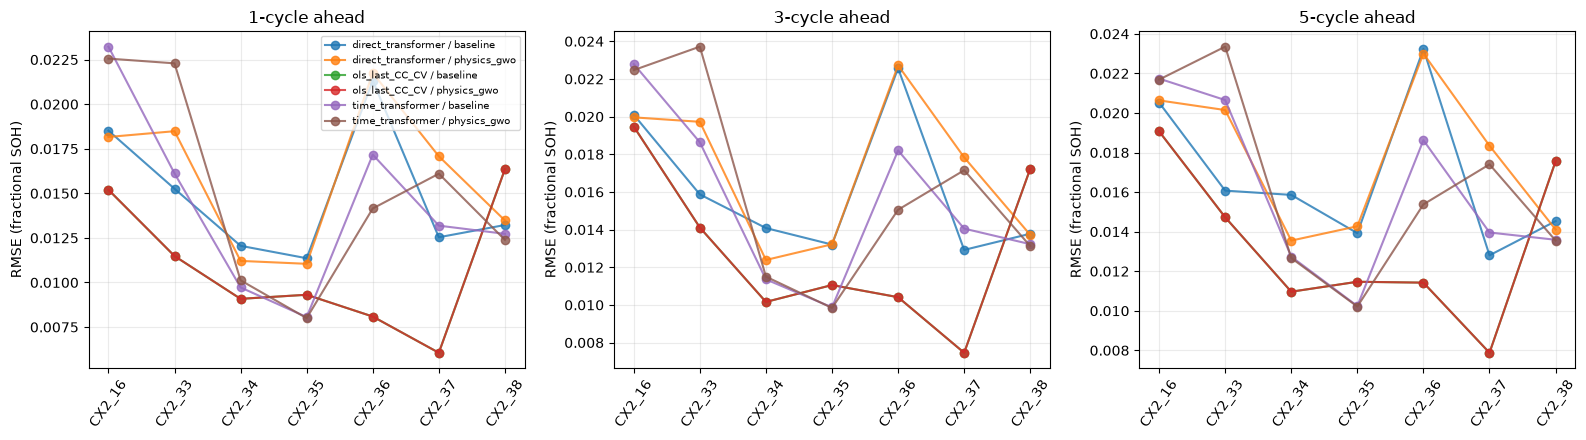

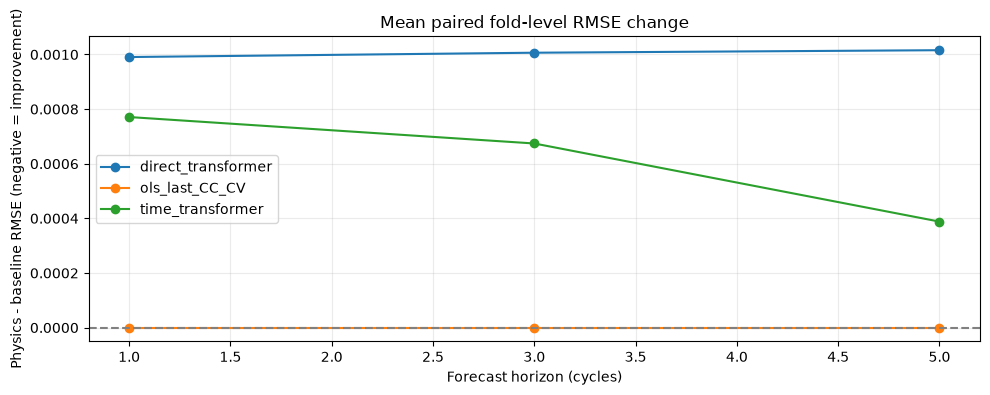

In [13]:
fig,axes=plt.subplots(1,3,figsize=(16,4.5),sharey=False)
for ax,h in zip(axes,HORIZONS):
    sub=outer.query('horizon==@h')
    for (fam,variant),part in sub.groupby(['model','variant']):
        part=part.sort_values('heldout')
        ax.plot(part['heldout'],part['RMSE'],marker='o',label=f'{fam} / {variant}',alpha=.8)
    ax.set_title(f'{h}-cycle ahead');ax.set_ylabel('RMSE (fractional SOH)')
    ax.tick_params(axis='x',rotation=55);ax.grid(alpha=.25)
axes[0].legend(fontsize=7)
plt.tight_layout();plt.savefig(OUTPUT_DIR/'fold_RMSE_comparison.png',dpi=150);plt.show()

fig,ax=plt.subplots(figsize=(10,4))
for name,grp in paired.groupby('model'):
    means=grp.groupby('horizon').delta_RMSE.mean().reindex(HORIZONS)
    ax.plot(HORIZONS,means,marker='o',label=name)
ax.axhline(0,linestyle='--',color='gray')
ax.set_xlabel('Forecast horizon (cycles)')
ax.set_ylabel('Physics - baseline RMSE (negative = improvement)')
ax.set_title('Mean paired fold-level RMSE change')
ax.legend();ax.grid(alpha=.25);plt.tight_layout()
plt.savefig(OUTPUT_DIR/'physics_effect_by_horizon.png',dpi=150);plt.show()

## 13. Interpretation and next steps

- **Primary conclusion:** for each model family, ask whether physics improves RMSE on *most* held-out cells without large regressions elsewhere. A good mean from one favorable cell is insufficient.
- **Constraint caution:** if predicted increases vanish but measured SOH frequently increases, monotonicity may be making the forecasts cosmetically smoother rather than more accurate.
- **Inactive bounds:** if out-of-bounds fractions are always zero, tune or remove bounds as a documented ablation; a nonzero GWO weight on an inactive term does not validate its physical importance.
- **Source quality:** the unexplained CX2_16 sawtooth fluctuations have not been independently validated. Treat any severe loss on that cell as diagnostic evidence, not grounds for secretly dropping it.
- **Robustness research:** if time or GWO effects are inconsistent, the next *separate* investigation should be feature-missingness-aware training and data-provenance encoding against strong imputation and linear controls.
- **Scientific precision:** This experiment uses soft phenomenological monotonicity/bounds priors, not a full electrochemical PINN. GWO tuning of such weights is not inherently novel.

**Deliverables:** `all_fold_metrics.csv`, `cross_cell_summary.csv`, `paired_cell_improvements.csv`, `paired_win_counts.csv`, `all_fold_physics_diagnostics.csv`, per-fold `gwo_search.csv`, checkpoints, prediction files, scaler, and audit metadata.